In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
!pip install cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.6/117.6 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 72.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.6/38.6 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.9/156.9 MB 10.8 MB/s eta 0:00:00
  Created wheel for cudaq: filename=cudaq-0.9.1-py3-none-any.whl size=6787 sha256=b155181036ccd0f5ba404b2cf6c2c6a28430e639605707a9a6d19bd58e25500c
  Stored in directory: /root/.cache/pip/wheels/b0/ee/32/0ac9053509c0ba31e4bac6122454996a9a4e4d6523b1918d04
Successfully built cudaq


In [ ]:
!pip install qutip


#Now testing and preperations are done, we shall move to the real work


##Reading the files and applying one hot encoding

In [ ]:
import os
from collections import Counter

# Path to the folder
folder_path = "/content/drive/MyDrive/Project_health_hackathon-20241112T014818Z-001/Project_health_hackathon/FastQ_raw"

# Get all files in the folder
file_list = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]

# Count total files
total_files = len(file_list)

# Extract file extensions
file_extensions = [os.path.splitext(f)[1] for f in file_list]

# Count file types
file_types_count = Counter(file_extensions)

# Print results
print(f"Total number of files: {total_files}")
print("File types and their counts:")
for ext, count in file_types_count.items():
    print(f"{ext if ext else 'No Extension'}: {count}")

Total number of files: 0
File types and their counts:


In [ ]:
!pip install transformers
!pip install tokenizers

#MODELS--Regression version





In [ ]:
import pandas as pd
import numpy as np
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import gzip

Prepare the x y data.

In [ ]:
import os
import pandas as pd
import numpy as np
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import gzip

# Placeholder functions for loading FASTQ sequences and one-hot encoding
def load_fastq_sequences(file_path, num_reads=1000):
    sequences = []
    with gzip.open(file_path, 'rt') as file:
        while len(sequences) < num_reads:
            file.readline()  # Read header
            sequence = file.readline().strip()  # Read sequence
            file.readline()  # Skip '+'
            file.readline()  # Skip quality score
            sequences.append(sequence)
    return sequences

def one_hot_encode_sequence(sequence, max_length=100):
    one_hot_mapping = {
        'A': [0, 0, 0, 1],
        'T': [0, 0, 1, 0],
        'G': [1, 0, 0, 0],
        'C': [0, 1, 0, 0]
    }
    encoded_sequence = [one_hot_mapping.get(nuc, [0, 0, 0, 0]) for nuc in sequence[:max_length]]
    if len(encoded_sequence) < max_length:
        encoded_sequence += [[0, 0, 0, 0]] * (max_length - len(encoded_sequence))
    return np.array(encoded_sequence)

# Path to the CSV file with metadata
csv_path = '/content/drive/MyDrive/health_hackathon/Project_health_hackathon/combined_metadata.csv'
sample_data = pd.read_csv(csv_path)

data = []  # Placeholder for one-hot encoded data
labels = []  # Placeholder for age labels

print("Processing Metadata and FASTQ Sequences:")

# Process each sample in the metadata
for index, sample in sample_data.iterrows():
    srr_id = sample.get("Run")
    age = sample.get("age")

    # Skip invalid samples
    if pd.isna(srr_id) or pd.isna(age):
        print(f"Skipping invalid sample at index {index}: {sample}")
        continue

    # Load sequences for single or paired-end files
    try:
        sequences = []

        # Check for paired-end files (_1 and _2)
        fastq_file_1 = f'/content/drive/MyDrive/health_hackathon/Project_health_hackathon/ENA_Downloads/{srr_id}_1.fastq.gz'
        fastq_file_2 = f'/content/drive/MyDrive/health_hackathon/Project_health_hackathon/ENA_Downloads/{srr_id}_2.fastq.gz'
        single_file = f'/content/drive/MyDrive/health_hackathon/Project_health_hackathon/ENA_Downloads/{srr_id}.fastq.gz'

        if os.path.exists(fastq_file_1) and os.path.exists(fastq_file_2):
            print(f"Processing paired-end files for {srr_id}...")
            seq_1 = load_fastq_sequences(fastq_file_1)
            seq_2 = load_fastq_sequences(fastq_file_2)
            sequences = [s1 + s2 for s1, s2 in zip(seq_1, seq_2)]  # Concatenate paired-end reads
        elif os.path.exists(single_file):
            print(f"Processing single-end file for {srr_id}...")
            sequences = load_fastq_sequences(single_file)
        else:
            print(f"No valid FASTQ file found for {srr_id}. Skipping.")
            continue

        # One-hot encode and flatten the sequences
        encoded_sequences = [one_hot_encode_sequence(seq) for seq in sequences]
        flattened_sequence = np.concatenate(encoded_sequences, axis=0)
        data.append(flattened_sequence)
        labels.append(age)
    except Exception as e:
        print(f"Error processing {srr_id}: {e}")
        continue

# Convert data and labels to NumPy arrays
if not data or not labels:
    raise ValueError("No valid data or labels found. Check metadata and FASTQ files.")
data = np.array(data)
labels = np.array(labels)

print(f"Data shape: {data.shape}")
print(f"Labels shape: {labels.shape}")

# Ensure the data shape is compatible with Conv1D
data = data.reshape(data.shape[0], -1, 4)

# Split into training, validation, and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

print(f"Training data shape: {X_train.shape}")
print(f"Validation data shape: {X_val.shape}")
print(f"Test data shape: {X_test.shape}")

Processing Metadata and FASTQ Sequences:
Processing paired-end files for SRR23920268...
Processing paired-end files for SRR23920267...
Processing paired-end files for SRR23920266...
Processing paired-end files for SRR23920265...
Processing paired-end files for SRR23920264...
Processing paired-end files for SRR23920263...
Processing paired-end files for SRR23920262...
Processing paired-end files for SRR23920261...
Processing paired-end files for SRR23920260...
Processing paired-end files for SRR23920259...
Processing paired-end files for SRR23920258...
Processing paired-end files for SRR23920257...
Processing paired-end files for SRR23920256...
Processing paired-end files for SRR23920255...
Processing paired-end files for SRR23920254...
Processing paired-end files for SRR23920253...
Processing paired-end files for SRR23920252...
Processing paired-end files for SRR23920251...
Processing paired-end files for SRR23920250...
Processing paired-end files for SRR23920249...
Processing paired-e

In [ ]:


# Define and build the CNN model
def build_cnn_model(input_shape):
    model = models.Sequential()
    model.add(layers.Conv1D(64, kernel_size=5, activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Conv1D(128, kernel_size=3, activation='relu'))
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation='relu'))  # Feature extraction layer
    return model

# Train the CNN
input_shape = (X_train.shape[1], X_train.shape[2])
cnn_model = build_cnn_model(input_shape)
cnn_model.add(layers.Dense(1, activation='linear'))  # Add the output layer
cnn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
cnn_model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val))

# Feature extraction from CNN
def extract_features(model, data):
    intermediate_model = models.Model(inputs=model.input, outputs=model.layers[-2].output)
    return intermediate_model.predict(data)

cnn_features_train = extract_features(cnn_model, X_train)
cnn_features_val = extract_features(cnn_model, X_val)
cnn_features_test = extract_features(cnn_model, X_test)

# Train Random Forest
scaler = StandardScaler()
cnn_features_train = scaler.fit_transform(cnn_features_train)
cnn_features_val = scaler.transform(cnn_features_val)
cnn_features_test = scaler.transform(cnn_features_test)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(cnn_features_train, y_train)

# Evaluate on test data
rf_predictions = rf_model.predict(cnn_features_test)
cnn_predictions = cnn_model.predict(X_test)

# Calculate evaluation metrics
cnn_mae = mean_absolute_error(y_test, cnn_predictions)
rf_mae = mean_absolute_error(y_test, rf_predictions)
print(f"CNN MAE on test data: {cnn_mae}")
print(f"Random Forest MAE on test data: {rf_mae}")

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - loss: 762037.3125 - mae: 501.6736 - val_loss: 537.4399 - val_mae: 17.8600
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - loss: 557.2350 - mae: 19.6801 - val_loss: 402.1681 - val_mae: 14.2953
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - loss: 281.3070 - mae: 11.6239 - val_loss: 210.5736 - val_mae: 12.7367
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - loss: 192.8759 - mae: 12.4824 - val_loss: 206.4644 - val_mae: 12.6468
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - loss: 172.6411 - mae: 11.2009 - val_loss: 231.2366 - val_mae: 12.2157
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - loss: 150.8839 - mae: 9.4941 - val_loss: 207.9221 - val_mae: 12.3313
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - loss: 130.9213 - mae: 9.6725 - val_loss: 204.3318 - val_mae: 12.3168
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - loss: 113.8904 - mae: 8.7804 - val_loss: 208.8766 - val_mae: 12.1926
Epoch 9/100
6/6 ━

ValueError: The layer sequential has never been called and thus has no defined input.

##Test the k-mers method

In [ ]:
print(f"Training data: {X_train}")

print(y_train)
print(len(X_train))
print(len(y_train))

Training data: [[[1 0 0 0]
  [0 1 0 0]
  [0 0 1 0]
  ...
  [0 0 0 0]
  [0 0 0 0]
  [0 0 0 0]]

 [[0 0 1 0]
  [0 0 0 0]
  [0 0 1 0]
  ...
  [0 1 0 0]
  [0 1 0 0]
  [1 0 0 0]]

 [[0 1 0 0]
  [0 0 0 0]
  [0 0 1 0]
  ...
  [0 1 0 0]
  [0 1 0 0]
  [0 0 1 0]]

 ...

 [[1 0 0 0]
  [0 0 0 1]
  [1 0 0 0]
  ...
  [0 0 0 1]
  [1 0 0 0]
  [0 0 0 1]]

 [[0 0 0 1]
  [0 0 0 0]
  [0 0 1 0]
  ...
  [1 0 0 0]
  [0 1 0 0]
  [0 0 0 1]]

 [[0 1 0 0]
  [0 0 1 0]
  [0 0 0 1]
  ...
  [0 0 0 0]
  [0 0 0 0]
  [0 0 0 0]]]
[20 31 62 28 29 59 25 53 20 18 65 25 48 25 74 20 77 20 18 28 26 26 24 31
 36 27 51 50 31 62 20 26 37 30 43 59 51 51 42 65 41 35 35 51 58 30 29 62
 35 38 30 30 26 58 36 59 30 62 20 31 19 30 20 42 29 29 62 71 51 20 29 20
 28 58 70 51 31 22 20 27 51 20 20 20 71 45 53 20 57 30 20 28 51 56 38 36
 21 62 20 20 29 20 23 33 58 77 62 30 58 33 29 20 56 20 65 29 58 65 28 29
 20 31 35 20 48 25 30 20 36 54 26 23 40 20 25 85 23 42 20 20 56 20 30 51
 35 58 23 22 62 30 43 65 21 29 18 20 31 58 20 36 59 27 20 28 

#test the transformer method with k-mers

In [ ]:
import os
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
import gzip
import torch
from torch.utils.data import Dataset

# First clone the DNABERT repository
!git clone https://github.com/jerryji1993/DNABERT.git
!mv DNABERT/ src/

# Install required dependencies
!pip install transformers
!pip install nvidia-pyindex
!pip install git+https://github.com/huggingface/transformers.git
!conda install pytorch torchvision cudatoolkit=10.0 -c pytorch

!cd DNABERT
!python3 -m pip install --editable .
!cd examples
!python3 -m pip install -r requirements.txt

Cloning into 'DNABERT'...
remote: Enumerating objects: 778, done.
remote: Counting objects: 100% (778/778), done.
remote: Compressing objects: 100% (348/348), done.
remote: Total 778 (delta 420), reused 721 (delta 407), pack-reused 0 (from 0)
Receiving objects: 100% (778/778), 11.66 MiB | 23.15 MiB/s, done.
Resolving deltas: 100% (420/420), done.
  Cloning https://github.com/huggingface/transformers.git to /tmp/pip-req-build-m7xun692
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/transformers.git /tmp/pip-req-build-m7xun692
  Resolved https://github.com/huggingface/transformers.git to commit 7547f55e5d93245c0a013b50df976924f2d9e8b0
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/bin/bash: line 1: conda: command not found
/bin/bash: line 1: cd: DNABERT: No such file or directory
Obtaining file:///content
ERROR: file:///content does not appear to be a Python proj

In [ ]:
# prompt: unzip this file /content/DNABERT/src/DNABERT/6-new-12w-0.zip

!unzip /content/DNABERT/src/DNABERT/6-new-12w-0.zip

unzip:  cannot find or open /content/DNABERT/src/DNABERT/6-new-12w-0.zip, /content/DNABERT/src/DNABERT/6-new-12w-0.zip.zip or /content/DNABERT/src/DNABERT/6-new-12w-0.zip.ZIP.


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Epoch 1/10
Train MAE: 34.88 | RMSE: 38.66 | R²: -4.44
Val   MAE: 36.82 | RMSE: 39.96 | R²: -5.63

Epoch 2/10
Train MAE: 31.70 | RMSE: 35.81 | R²: -3.67
Val   MAE: 34.75 | RMSE: 38.06 | R²: -5.01

Epoch 3/10
Train MAE: 29.72 | RMSE: 34.07 | R²: -3.23
Val   MAE: 32.57 | RMSE: 36.08 | R²: -4.40

Epoch 4/10
Train MAE: 27.44 | RMSE: 32.05 | R²: -2.74
Val   MAE: 30.13 | RMSE: 33.89 | R²: -3.77

Epoch 5/10
Train MAE: 24.86 | RMSE: 29.89 | R²: -2.25
Val   MAE: 27.39 | RMSE: 31.48 | R²: -3.12

Epoch 6/10
Train MAE: 21.99 | RMSE: 27.64 | R²: -1.78
Val   MAE: 24.40 | RMSE: 28.92 | R²: -2.47

Epoch 7/10
Train MAE: 19.05 | RMSE: 25.29 | R²: -1.33
Val   MAE: 21.43 | RMSE: 26.45 | R²: -1.91

Epoch 8/10
Train MAE: 16.67 | RMSE: 23.14 | R²: -0.95
Val   MAE: 18.97 | RMSE: 24.08 | R²: -1.41

Epoch 9/10
Train MAE: 15.21 | RMSE: 21.14 | R²: -0.63
Val   MAE: 16.76 | RMSE: 22.06 | R²: -1.02

Epoch 10/10
Train MAE: 14.02 | RMSE: 19.60 | R²: -0.40
Val   MAE: 14.79 | RMSE: 20.20 | R²: -0.69

Epoch 11/10
Train M

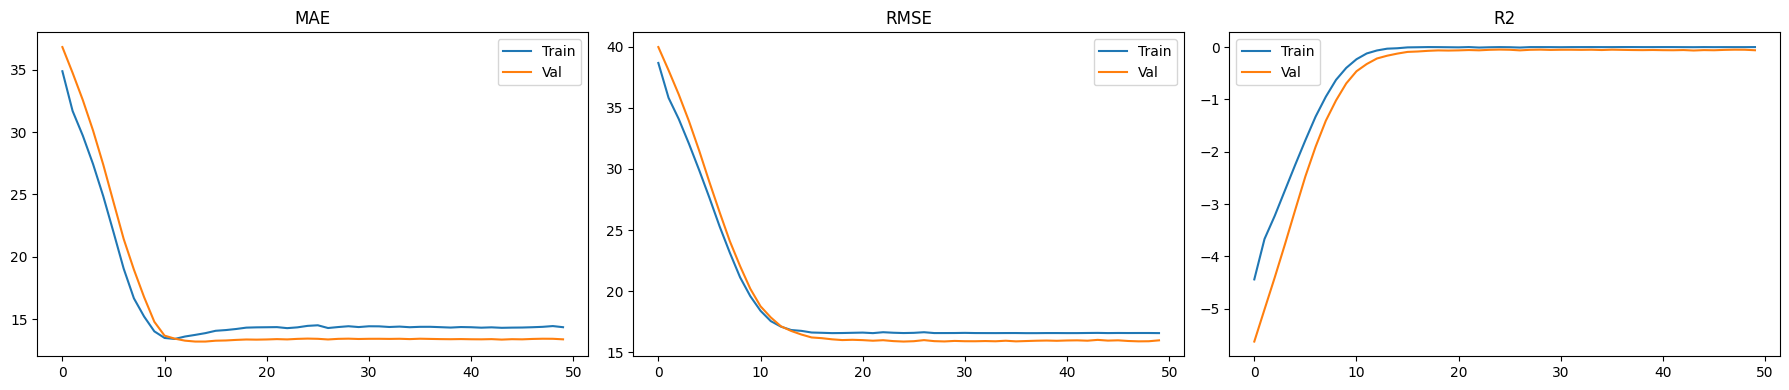

True Age: 20.0 | Predicted Age: 37.6
Absolute Error: 17.6 years
Percentage Error: 88.2%



RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

class LargeRNAModel(nn.Module):
    def __init__(self, input_dim=4, seq_len=100000):
        super().__init__()

        # CNN Downsampling Block
        self.downsample = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=16, stride=8),  # 100000 -> 12499
            nn.ReLU(),
            nn.MaxPool1d(4),  # 12499 -> 3124
            nn.Conv1d(64, 128, kernel_size=8, stride=4),  # 3124 -> 780
            nn.ReLU(),
            nn.Conv1d(128, 256, kernel_size=4, stride=2),  # 780 -> 389
        )

        # Transformer Block
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=256,
                nhead=8,
                dim_feedforward=512,
                dropout=0.1
            ),
            num_layers=4
        )

        # Regression Head
        self.regressor = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

        # Positional encoding
        self.pos_encoder = nn.Parameter(torch.randn(1, 256, 389))

    def forward(self, x):
        # Input shape: (batch, seq_len, 4)
        x = x.permute(0, 2, 1)  # (batch, 4, seq_len)
        x = self.downsample(x)  # (batch, 256, 389)
        x += self.pos_encoder
        x = x.permute(2, 0, 1)  # (389, batch, 256)
        transformer_out = self.transformer(x)
        pooled = transformer_out.mean(dim=0)  # (batch, 256)
        return self.regressor(pooled).squeeze()

def calculate_metrics(y_true, y_pred):
    """Calculate regression metrics"""
    return {
        'mae': torch.abs(y_true - y_pred).mean().item(),
        'mse': torch.mean((y_true - y_pred)**2).item(),
        'rmse': torch.sqrt(torch.mean((y_true - y_pred)**2)).item(),
        'r2': 1 - (torch.sum((y_true - y_pred)**2) / torch.sum((y_true - y_true.mean())**2)).item()
    }

def train_large_model(X_train, y_train, X_val, y_val):
    """Training function with metrics tracking"""
    train_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                             torch.tensor(y_train, dtype=torch.float32))
    val_data = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                           torch.tensor(y_val, dtype=torch.float32))

    train_loader = DataLoader(train_data, batch_size=8, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=8)

    model = LargeRNAModel()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    criterion = nn.MSELoss()

    best_r2 = -float('inf')
    history = {'train': [], 'val': []}

    for epoch in range(50):
        # Training phase
        model.train()
        train_preds, train_labels = [], []
        for seq, lbl in train_loader:
            optimizer.zero_grad()
            pred = model(seq)
            loss = criterion(pred, lbl)
            loss.backward()
            optimizer.step()
            train_preds.append(pred.detach())
            train_labels.append(lbl.detach())

        # Validation phase
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for seq, lbl in val_loader:
                val_preds.append(model(seq))
                val_labels.append(lbl)

        # Calculate metrics
        train_metrics = calculate_metrics(torch.cat(train_labels), torch.cat(train_preds))
        val_metrics = calculate_metrics(torch.cat(val_labels), torch.cat(val_preds))

        # Save best model
        if val_metrics['r2'] > best_r2:
            best_r2 = val_metrics['r2']
            torch.save(model.state_dict(), 'best_model.pth')

        # Store history
        history['train'].append(train_metrics)
        history['val'].append(val_metrics)

        # Print metrics
        print(f"Epoch {epoch+1}/10")
        print(f"Train MAE: {train_metrics['mae']:.2f} | RMSE: {train_metrics['rmse']:.2f} | R²: {train_metrics['r2']:.2f}")
        print(f"Val   MAE: {val_metrics['mae']:.2f} | RMSE: {val_metrics['rmse']:.2f} | R²: {val_metrics['r2']:.2f}\n")

    # Plot training history
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    metrics = ['mae', 'rmse', 'r2']
    for i, metric in enumerate(metrics):
        ax[i].plot([m[metric] for m in history['train']], label='Train')
        ax[i].plot([m[metric] for m in history['val']], label='Val')
        ax[i].set_title(metric.upper())
        ax[i].legend()
    plt.tight_layout()
    plt.show()

    return model

def interpret_large_model(model, sample_input, true_label, original_length=100000):
    """Interpretation with prediction metrics and feature importance"""
    # Make prediction
    with torch.no_grad():
        pred = model(torch.tensor(sample_input[None], dtype=torch.float32)).item()

    # Prediction metrics
    print(f"True Age: {true_label:.1f} | Predicted Age: {pred:.1f}")
    print(f"Absolute Error: {abs(true_label - pred):.1f} years")
    print(f"Percentage Error: {abs(true_label - pred)/true_label*100:.1f}%\n")

    # Feature importance analysis
    activations = []
    def hook_fn(_, __, output): activations.append(output.detach())

    hook = model.downsample[0].register_forward_hook(hook_fn)
    model(torch.tensor(sample_input[None], dtype=torch.float32))
    hook.remove()

    # Calculate gradients
    model.zero_grad()
    torch.tensor(pred).backward()
    gradients = model.downsample[0].weight.grad.abs().mean(dim=(0,1)).cpu().numpy()

    # Map to original sequence
    importance = np.zeros(original_length)
    kernel_size, stride = 16, 8
    for i, grad in enumerate(gradients):
        start = i * stride
        end = start + kernel_size
        importance[start:end] += grad

    # Normalize and plot
    importance = (importance - importance.min()) / (importance.max() - importance.min())
    plt.figure(figsize=(20, 4))
    plt.plot(importance)
    plt.title("Genomic Region Importance", fontsize=14)
    plt.xlabel("Sequence Position", fontsize=12)
    plt.ylabel("Normalized Importance", fontsize=12)
    plt.show()

    # Top important regions
    window_size = 1000
    smoothed = np.convolve(importance, np.ones(window_size)/window_size, 'same')
    top_regions = np.argsort(-smoothed)[:10]

    print("Top Important Genomic Regions:")
    for pos in top_regions:
        start = max(0, pos-500)
        end = min(original_length, pos+500)
        print(f"Region {start:,}-{end:,} (center {pos:,})")

# Usage example
model = train_large_model(X_train, y_train, X_val, y_val)
interpret_large_model(model, X_test[0], y_test[0])

#Hypird Model

In [ ]:
import sys
sys.path.append("/content/QuantumTransformers-main/")


In [ ]:
from quantum_transformers.quantum_layer import get_circuit
from quantum_transformers.transformers import VisionTransformer
from quantum_transformers.training import train_and_evaluate


In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from quantum_transformers.transformers import VisionTransformer
from quantum_transformers.quantum_layer import get_circuit

class LargeRNAModel(nn.Module):
    def __init__(self, input_dim=4, seq_len=100000):
        super().__init__()

        # CNN Downsampling Block
        self.downsample = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=16, stride=8),  # Reduce seq_len
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(64, 128, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv1d(128, 256, kernel_size=4, stride=2),
        )

        # Quantum Vision Transformer
        self.qvt = VisionTransformer(
            num_classes=1,  # Regression task, so output = 1
            patch_size=10,  # Tune this based on input resolution
            hidden_size=256,  # Must match CNN output channels
            num_heads=8,
            num_transformer_blocks=4,
            mlp_hidden_size=512,
            quantum_attn_circuit=get_circuit(),  # Quantum Self-Attention
            quantum_mlp_circuit=get_circuit()  # Quantum MLP
        )

        # Positional encoding (optional)
        self.pos_encoder = nn.Parameter(torch.randn(1, 256, 389))

        # Regression Head
        self.regressor = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
       x = x.permute(0, 2, 1)  # Adjust input shape
       x = self.downsample(x)  # (batch, 256, reduced_seq_len)
       pos_enc_resized = torch.nn.functional.interpolate(
        self.pos_encoder, size=x.shape[-1], mode='linear', align_corners=False
    )
       x += pos_enc_resized  # Ensure shape compatibility
       x = x.permute(2, 0, 1)  # (seq_len, batch, features)
       x = self.qvt(x, train=True)
       pooled = x.mean(dim=1)

       return self.regressor(pooled).squeeze()




In [ ]:
import jax
import jax.numpy as jnp

# Sample Data
X_train = np.random.randn(100, 1000, 4)  # (samples, seq_len, features)
y_train = np.random.randn(100)  # Regression target

# Convert to tensors
train_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                           torch.tensor(y_train, dtype=torch.float32))
train_loader = DataLoader(train_data, batch_size=8, shuffle=True)

# Initialize Model
model = LargeRNAModel()

# Run a forward pass
sample_input = torch.randn(8, 1000, 4)  # Batch size 8

# Define PRNG Key
rng = jax.random.PRNGKey(0)

# Initialize Model (Creates Parameters)
variables = model.init(rng, jnp.ones((1, 1000, 4)))  # Ensure shape matches your input

# Run Forward Pass with Initialized Model
output = model.apply(variables, sample_input)

print("Output Shape:", output.shape)  # Should be (8,)





CallCompactUnboundModuleError: Can't call compact methods on unbound modules (https://flax.readthedocs.io/en/latest/api_reference/flax.errors.html#flax.errors.CallCompactUnboundModuleError)

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import torch
import torch.nn as nn
import numpy as np
from torch.autograd import Function
import cudaq

In [ ]:


# ------------------- QUANTUM FUNCTION -------------------
class QuantumFunction(Function):
    """Quantum function with custom expectation values and gradients."""

    def __init__(self, qubit_count: int, hamiltonian: cudaq.SpinOperator):
        """Define the quantum circuit and Hamiltonian measurement."""

        @cudaq.kernel
        def kernel(qubit_count: int, thetas: np.ndarray):
            qubits = cudaq.qvector(qubit_count)
            for i in range(qubit_count):
                ry(thetas[i], qubits[i])
                rx(thetas[i], qubits[i])
            for i in range(qubit_count - 1):
                x.ctrl(qubits[i], qubits[i + 1])

        self.kernel = kernel
        self.qubit_count = qubit_count
        self.hamiltonian = hamiltonian

    def run(self, theta_vals: torch.Tensor) -> torch.Tensor:
        """Run quantum circuit and return expectation values."""
        results = cudaq.observe(self.kernel, self.hamiltonian, self.qubit_count, theta_vals.tolist())
        exp_vals = [results[i].expectation() for i in range(len(results))]
        return torch.tensor(exp_vals, dtype=torch.float32)

    @staticmethod
    def forward(ctx, thetas: torch.Tensor, quantum_circuit, shift) -> torch.Tensor:
        """Forward pass: Compute expectation value."""
        ctx.shift = shift
        ctx.quantum_circuit = quantum_circuit

        exp_vals = ctx.quantum_circuit.run(thetas).reshape(-1, 1)
        ctx.save_for_backward(thetas, exp_vals)

        return exp_vals

    @staticmethod
    def backward(ctx, grad_output):
        """Backward pass: Compute gradients via finite difference."""
        thetas, _ = ctx.saved_tensors
        gradients = torch.zeros_like(thetas)

        for i in range(thetas.shape[1]):
            thetas_plus = thetas.clone()
            thetas_plus[:, i] += ctx.shift
            exp_vals_plus = ctx.quantum_circuit.run(thetas_plus)

            thetas_minus = thetas.clone()
            thetas_minus[:, i] -= ctx.shift
            exp_vals_minus = ctx.quantum_circuit.run(thetas_minus)

            gradients[:, i] = (exp_vals_plus - exp_vals_minus) / (2 * ctx.shift)

        return grad_output * gradients, None, None


In [ ]:
class QuantumLayer(nn.Module):
    """Quantum Layer for hybrid neural networks."""

    def __init__(self, qubit_count: int, hamiltonian, shift: torch.Tensor):
        super(QuantumLayer, self).__init__()
        self.quantum_circuit = QuantumFunction(qubit_count, hamiltonian)
        self.shift = shift

    def forward(self, input):
        return QuantumFunction.apply(input, self.quantum_circuit, self.shift)


In [ ]:


class LargeRNAModel(nn.Module):
    def __init__(self, input_dim=4, seq_len=100000, qubit_count=4, hamiltonian=None, shift=torch.tensor(np.pi / 4)):
        super().__init__()

        # ------------------- CNN Downsampling Block -------------------
        self.downsample = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=16, stride=8),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(64, 128, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv1d(128, 256, kernel_size=4, stride=2),
        )

        # ------------------- Quantum Layer -------------------
        self.quantum = QuantumLayer(qubit_count, hamiltonian, shift)

        # ------------------- Transformer Block -------------------
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model=256, nhead=8, dim_feedforward=512, dropout=0.1),
            num_layers=4
        )

        # ------------------- Regression Head -------------------
        self.regressor = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

        # ------------------- Positional Encoding -------------------
        self.pos_encoder = nn.Parameter(torch.randn(1, 256, 389))

    def forward(self, x):
        x = x.permute(0, 2, 1)  # (batch, 4, seq_len) → (batch, seq_len, 4)
        x = self.downsample(x)  # CNN Feature Extraction → (batch, 256, 389)
        x += self.pos_encoder

        x = x.permute(2, 0, 1)  # Shape for Transformer: (389, batch, 256)
        transformer_output = self.transformer(x)

        # ------------------- Apply Quantum Layer -------------------
        quantum_output = self.quantum(transformer_output)

        # ------------------- Apply Regression Head -------------------
        pooled = quantum_output.mean(dim=1)  # (batch, 256)
        return self.regressor(pooled).squeeze()




In [ ]:
def calculate_metrics(y_true, y_pred):
    """Calculate regression metrics"""
    return {
        'mae': torch.abs(y_true - y_pred).mean().item(),
        'mse': torch.mean((y_true - y_pred)**2).item(),
        'rmse': torch.sqrt(torch.mean((y_true - y_pred)**2)).item(),
        'r2': 1 - (torch.sum((y_true - y_pred)**2) / torch.sum((y_true - y_true.mean())**2)).item()
    }

def train_large_model(X_train, y_train, X_val, y_val, qubit_count, hamiltonian):
    """Training function for Hybrid QSANN."""
    train_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
    val_data = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))

    train_loader = DataLoader(train_data, batch_size=8, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=8)

    model = LargeRNAModel(input_dim=4, seq_len=100000, qubit_count=qubit_count, hamiltonian=hamiltonian)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    criterion = nn.MSELoss()
    best_r2 = -float('inf')
    history = {'train': [], 'val': []}

    for epoch in range(50):
        # Training phase
        model.train()
        train_preds, train_labels = [], []
        for seq, lbl in train_loader:
            optimizer.zero_grad()
            pred = model(seq)
            loss = criterion(pred, lbl)
            loss.backward()
            optimizer.step()
            train_preds.append(pred.detach())
            train_labels.append(lbl.detach())

        # Validation phase
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for seq, lbl in val_loader:
                val_preds.append(model(seq))
                val_labels.append(lbl)

        # Calculate metrics
        train_metrics = calculate_metrics(torch.cat(train_labels), torch.cat(train_preds))
        val_metrics = calculate_metrics(torch.cat(val_labels), torch.cat(val_preds))

        # Save best model
        if val_metrics['r2'] > best_r2:
            best_r2 = val_metrics['r2']
            torch.save(model.state_dict(), 'best_model.pth')

        # Store history
        history['train'].append(train_metrics)
        history['val'].append(val_metrics)

        # Print metrics
        print(f"Epoch {epoch+1}/10")
        print(f"Train MAE: {train_metrics['mae']:.2f} | RMSE: {train_metrics['rmse']:.2f} | R²: {train_metrics['r2']:.2f}")
        print(f"Val   MAE: {val_metrics['mae']:.2f} | RMSE: {val_metrics['rmse']:.2f} | R²: {val_metrics['r2']:.2f}\n")

    # Plot training history
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    metrics = ['mae', 'rmse', 'r2']
    for i, metric in enumerate(metrics):
        ax[i].plot([m[metric] for m in history['train']], label='Train')
        ax[i].plot([m[metric] for m in history['val']], label='Val')
        ax[i].set_title(metric.upper())
        ax[i].legend()
    plt.tight_layout()
    plt.show()

    return model



In [ ]:
def interpret_large_model(model, sample_input, true_label, original_length=100000):
    """Interpretation with prediction metrics and feature importance"""
    # Make prediction
    with torch.no_grad():
        pred = model(torch.tensor(sample_input[None], dtype=torch.float32)).item()

    # Prediction metrics
    print(f"True Age: {true_label:.1f} | Predicted Age: {pred:.1f}")
    print(f"Absolute Error: {abs(true_label - pred):.1f} years")
    print(f"Percentage Error: {abs(true_label - pred)/true_label*100:.1f}%\n")

    # Feature importance analysis
    activations = []
    def hook_fn(_, __, output): activations.append(output.detach())

    hook = model.downsample[0].register_forward_hook(hook_fn)
    model(torch.tensor(sample_input[None], dtype=torch.float32))
    hook.remove()

    # Calculate gradients
    model.zero_grad()
    torch.tensor(pred).backward()
    gradients = model.downsample[0].weight.grad.abs().mean(dim=(0,1)).cpu().numpy()

    # Map to original sequence
    importance = np.zeros(original_length)
    kernel_size, stride = 16, 8
    for i, grad in enumerate(gradients):
        start = i * stride
        end = start + kernel_size
        importance[start:end] += grad

    # Normalize and plot
    importance = (importance - importance.min()) / (importance.max() - importance.min())
    plt.figure(figsize=(20, 4))
    plt.plot(importance)
    plt.title("Genomic Region Importance", fontsize=14)
    plt.xlabel("Sequence Position", fontsize=12)
    plt.ylabel("Normalized Importance", fontsize=12)
    plt.show()

    # Top important regions
    window_size = 1000
    smoothed = np.convolve(importance, np.ones(window_size)/window_size, 'same')
    top_regions = np.argsort(-smoothed)[:10]

    print("Top Important Genomic Regions:")
    for pos in top_regions:
        start = max(0, pos-500)
        end = min(original_length, pos+500)
        print(f"Region {start:,}-{end:,} (center {pos:,})")

# Usage example
model = train_large_model(X_train, y_train, X_val, y_val, qubit_count, hamiltonian)
interpret_large_model(model, X_test[0], y_test[0])

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



TypeError: train_large_model() missing 2 required positional arguments: 'qubit_count' and 'hamiltonian'

During handling of the above exception, another exception occurred:

AttributeError: 'TypeError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

AssertionError
TypeError: train_large_model() missing 2 required positional arguments: 'qubit_count' and 'hamiltonian'

During handling of the above exception, another exception occurred:

AttributeError: 'TypeError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

TypeError: object of type 'NoneType' has no len()

During handling of the above exception, another exception occurred:

AttributeError: 'TypeError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

AssertionError
TypeError: train_large_model() missing 2 required positional arguments: '

<ipython-input-24-3d7f3dda5ce0>:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



AssertionError: Size mismatch between tensors

During handling of the above exception, another exception occurred:

AttributeError: 'AssertionError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

AssertionError
AssertionError: Size mismatch between tensors

During handling of the above exception, another exception occurred:

AttributeError: 'AssertionError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

TypeError: object of type 'NoneType' has no len()

During handling of the above exception, another exception occurred:

AttributeError: 'TypeError' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

AssertionError
AssertionError: Size mismatch between tensors

During handling of the above exception, another exception occurred:

AttributeError: 'AssertionError' object has no attribute '_rend